# SAE-MAS layer 25: where we are

**Do the SAE features that predict feedback adoption control it?** Baseline · Exp 1 custom SAE (TopK) · Exp 2 pretrained SAE · Control 1 no ablation · Control 2 random ablations. Every number is read from committed files.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
TOPK = ROOT / "results/causal_topk_mixed_layer25/20261103T024624099539Z/distributed/merged_exclude_empty6"
RUNB = ROOT / "results/causal_reconstruction_control_layer25/20261103T202307480433Z"
PROBE = ROOT / "results/probe_mixed_final_001_layer25/20261102T185349607791Z"
FT = ROOT / "results/sae/decoder_finetuning/20261102T205853702830Z"
AUDIT = ROOT / "results/causal_pretrained_layer25/edit_norm_audit.json"
LAYERS = ROOT / "results/layer_selection_mixed_final_001_quick/20261102T201434082931Z"          # after the feedback
MATCHED = ROOT / "results/probe_mixed_final_001_layer25/matched_edits/20261102T202029069203Z"     # offline equal-size edits
LAYERS_A1 = ROOT / "results/layer_selection_mixed_final_001_attempt1_quick/20261102T230955770186Z"  # before it
OUT = ROOT / "reports/figures/causal_layer25_where_we_are"
(OUT / "tables").mkdir(parents=True, exist_ok=True)

INPUTS = [TOPK / n for n in ("targeted_vs_random.csv", "causal_table.csv", "diagnostics.csv", "control_match.csv",
                             "changed_answers.csv", "episodes.csv", "replay_check.json", "claude_labeled/summary.json", "derived_from.json", "replay_config.json")]
INPUTS += [RUNB / n for n in ("reconstruction_damage.csv", "claude_labeled/summary.json", "replay_check.json")]
INPUTS += [PROBE / "feature_selection_summary.json", PROBE / "causal_proxy_table.csv", FT / "summary.json", FT / "manifest.json", AUDIT]
INPUTS += [d / n for d in (LAYERS, LAYERS_A1) for n in ("layer_comparison.csv", "layer_selection_summary.json")]
INPUTS += [MATCHED / "matched_edit_summary.json", MATCHED / "matched_effects.csv"]
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
BEFORE = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}

csv = lambda d, n: pd.read_csv(d / n)
js = lambda d, n: json.loads((d / n).read_text())
tvr, topk_table, topk_diag, match = (csv(TOPK, n) for n in ("targeted_vs_random.csv", "causal_table.csv", "diagnostics.csv", "control_match.csv"))
topk_check, topk_labels, topk_derived = (js(TOPK, n) for n in ("replay_check.json", "claude_labeled/summary.json", "derived_from.json"))
topk_cfg = js(TOPK, "replay_config.json")["config"]
damage, runb_labels, runb_check = csv(RUNB, "reconstruction_damage.csv"), js(RUNB, "claude_labeled/summary.json"), js(RUNB, "replay_check.json")
probe, proxy = js(PROBE, "feature_selection_summary.json"), csv(PROBE, "causal_proxy_table.csv")
ft_summary, ft_manifest, audit = js(FT, "summary.json"), js(FT, "manifest.json"), json.loads(AUDIT.read_text())
changed, topk_eps = csv(TOPK, "changed_answers.csv"), csv(TOPK, "episodes.csv")
matched, matched_effects = js(MATCHED, "matched_edit_summary.json"), csv(MATCHED, "matched_effects.csv")
layers, layers_a1, layer_cfg = csv(LAYERS, "layer_comparison.csv"), csv(LAYERS_A1, "layer_comparison.csv"), js(LAYERS, "layer_selection_summary.json")["config"]
UPSTREAM = {"labeled": 10105, "adoption": 1814, "retention": 1704}   # source Claude labeling run (claude_validation/mixed_final_001/intervention)
assert topk_check["passed"] and runb_check["passed"] and layer_cfg["n_permutations"] == 0

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"font.family": ["Arial", "DejaVu Sans"], "font.size": 11, "svg.fonttype": "none", "svg.hashsalt": "where-we-are",
                     "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.color": INK2,
                     "ytick.labelcolor": INK, "figure.dpi": 110})


def one(df, **where):
    """The single row matching every column=value; anything else is an error, never a silent pick."""
    hit = df
    for col, val in where.items():
        hit = hit[hit[col] == val]
    if len(hit) != 1:
        raise ValueError(f"expected one row for {where}, got {len(hit)}")
    return hit.iloc[0]


def ci(text):
    return tuple(float(v) for v in str(text).strip("[]").split(","))


fmt_p = lambda p: f"{p:.4f}" if p < 0.001 else f"{p:.3f}" if p < 0.01 else f"{p:.2f}"


def show(df, name):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    display(df.style.hide(axis="index"))


def axes(title, size=(9.5, 4.0), grid="x", left=None):
    fig, ax = plt.subplots(figsize=size)
    if left:
        fig.subplots_adjust(left=left)
    for side in ("top", "right", "left" if grid == "x" else "top"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(axis=grid, color=GRID, linewidth=1); ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=12)
    return fig, ax


def save(fig, name):
    fig.savefig(OUT / f"{name}.svg", bbox_inches="tight", pad_inches=0.25, metadata={"Date": None})
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", pad_inches=0.25, metadata={"CreationDate": None})
    plt.show()


def forest(ax, rows, xlim):
    """rows: (label, estimate, lo, hi, significant) top to bottom."""
    for i, (label, m, lo, hi, sig) in enumerate(rows):
        c = BLUE if sig else MUTED
        ax.plot([lo, hi], [i, i], color=c, linewidth=2, solid_capstyle="round", zorder=2)
        ax.scatter([m], [i], s=60, color=c, edgecolors=SURF, linewidths=2, zorder=3)
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis(); ax.set_xlim(*xlim)

## 1 · Data

In [2]:
show(pd.DataFrame([
    ("Intervention episodes labeled by Claude", f"{UPSTREAM['labeled']:,}"),
    ("Eligible (Adoption + Retention)", f"{UPSTREAM['adoption'] + UPSTREAM['retention']:,}"),
    ("Exp 1 TopK: first episodes of the seed-42 order", f"{topk_cfg['limit']} (replay exact {topk_check['mismatch_counts']['exact_match']}/{topk_check['n_episodes']})"),
    ("Exp 1 analysed", f"{topk_labels['n_analysis_episodes']}"),
    ("Control 1 and Exp 2: first 250 of the same order", f"Control 1 analysed {runb_labels['n_analysis_episodes']}"),
], columns=["", "Episodes"]), "1_data")

,Episodes
Intervention episodes labeled by Claude,"10,105"
Eligible (Adoption + Retention),"3,518"
Exp 1 TopK: first episodes of the seed-42 order,500 (replay exact 500/500)
Exp 1 analysed,494
Control 1 and Exp 2: first 250 of the same order,Control 1 analysed 249


## 2 · The decision is readable from the activations (probes)

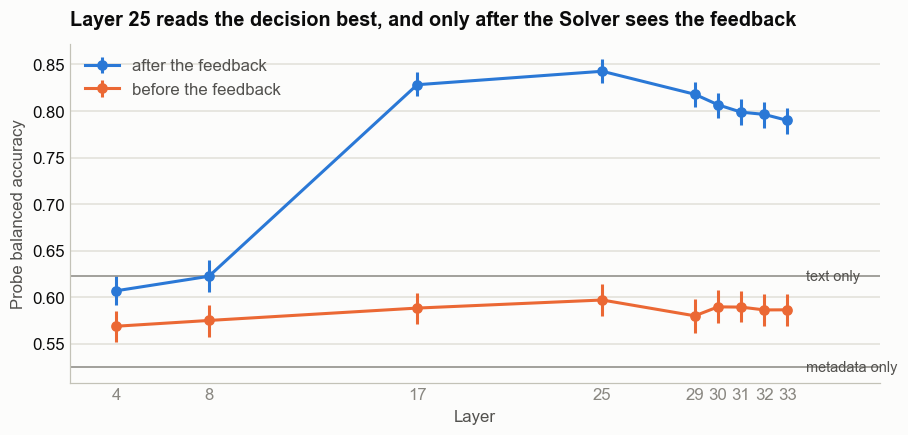

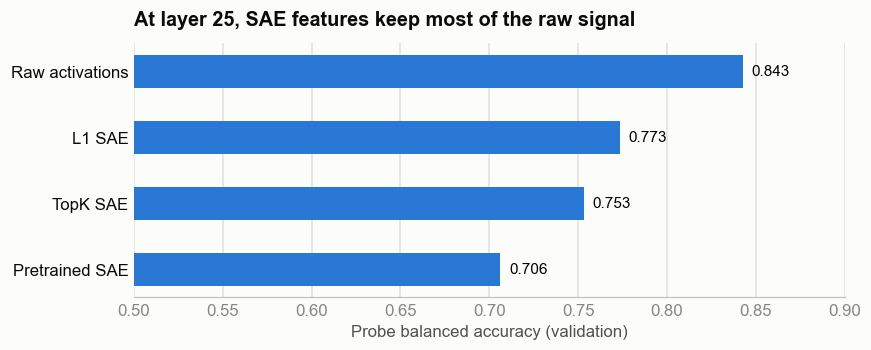

In [3]:
L = lambda df: df[df.name.str.startswith("layer_")].assign(layer=lambda d: d.name.str[6:].astype(int)).sort_values("layer")
after, before = L(layers), L(layers_a1)
fig, ax = axes("Layer 25 reads the decision best, and only after the Solver sees the feedback", grid="y")
for df, color, label in ((after, BLUE, "after the feedback"), (before, ORANGE, "before the feedback")):
    ax.errorbar(df.layer, df.balanced_accuracy, yerr=[df.balanced_accuracy - df.ci95_lo, df.ci95_hi - df.balanced_accuracy],
                color=color, marker="o", markersize=6, linewidth=2, label=label)
for base, text in (("text_only_baseline", "text only"), ("metadata_baseline", "metadata only")):
    v = float(one(layers, name=base)["balanced_accuracy"]); ax.axhline(v, color=MUTED, linewidth=1)
    ax.text(33.8, v, text, va="center", fontsize=9.5, color=INK2)
ax.set_xticks(after.layer); ax.set_xlim(2, 37); ax.set_xlabel("Layer"); ax.set_ylabel("Probe balanced accuracy")
ax.legend(loc="upper left", frameon=False, labelcolor=INK2)
save(fig, "2a_layers")

reps = {n: t for n, t in probe["saes"].items()}
fig, ax = axes("At layer 25, SAE features keep most of the raw signal", size=(9.5, 3.0), left=0.22)
names = list(reps)[::-1]
ax.barh(names, [reps[n]["probe"]["balanced_accuracy_eval"] for n in names], height=0.5, color=BLUE)
for i, n in enumerate(names):
    ax.text(reps[n]["probe"]["balanced_accuracy_eval"] + 0.005, i, f"{reps[n]['probe']['balanced_accuracy_eval']:.3f}", va="center", fontsize=10)
ax.set_xlim(0.5, 0.9); ax.set_xlabel("Probe balanced accuracy (validation)")
save(fig, "2b_representations")

## 2c · Offline: equal-size edits move the probe's prediction more than random edits

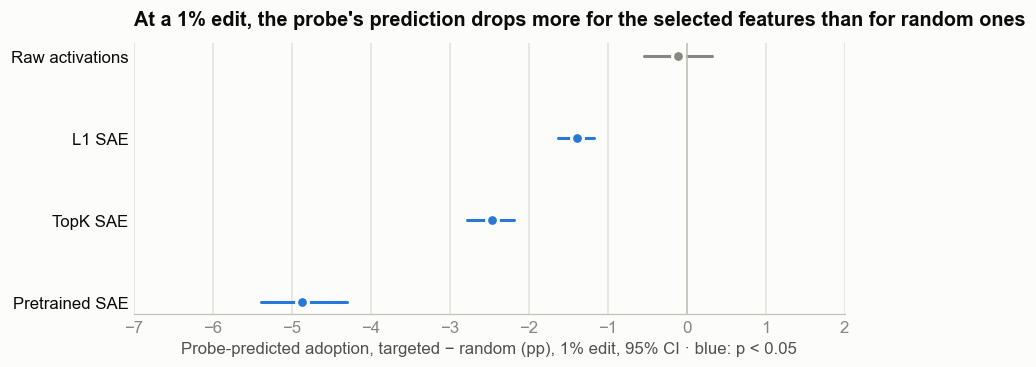

Representation (top 10),Edit size,Targeted − random (pp),95% CI,p
Raw activations,1%,-0.110000,"[-0.54, 0.32]",0.62
Raw activations,2.5%,-1.110000,"[-2.07, -0.22]",0.02
Raw activations,5%,-3.400000,"[-4.85, -1.96]",0.0001
Raw activations,10%,-4.490000,"[-6.27, -2.74]",0.0001
L1 SAE,1%,-1.390000,"[-1.62, -1.18]",0.0001
L1 SAE,2.5%,-3.570000,"[-4.18, -3.03]",0.0001
L1 SAE,5%,-7.130000,"[-8.35, -6.04]",0.0001
L1 SAE,10%,-12.260000,"[-14.40, -10.41]",0.0001
TopK SAE,1%,-2.470000,"[-2.78, -2.19]",0.0001
TopK SAE,2.5%,-6.210000,"[-6.98, -5.49]",0.0001


Offline readout predictions only (one raw-activation readout, 3,227 validation episodes). Above 1% the readout saturates (random directions at 5% span 0.0–100.0% predicted adoption) and pretrained edits exceed that set's own full-ablation size (§5), so 1% is the comparable column. The raw probe direction (-50.5 pp) is a deliberately favourable benchmark for this same readout, not causal evidence.


In [4]:
rows, table = [], []
for rep, results in matched["targeted_vs_random"].items():
    for r in results:
        lo, hi = r["ci95_pp_questions_and_draws"]
        table.append({"Representation (top 10)": rep, "Edit size": f"{100 * r['dose']:g}%",
                      "Targeted − random (pp)": round(r["delta_pp"], 2), "95% CI": f"[{lo:.2f}, {hi:.2f}]", "p": fmt_p(r["p_value"])})
        if r["dose"] == 0.01:
            rows.append((rep, r["delta_pp"], lo, hi, r["p_value"] < 0.05))
bench = float(one(matched_effects, representation="Raw probe direction", dose=0.01)["delta_pp"])
fig, ax = axes("At a 1% edit, the probe's prediction drops more for the selected features than for random ones", size=(9.5, 3.2), left=0.22)
forest(ax, rows, (-7, 2)); ax.set_xlabel("Probe-predicted adoption, targeted − random (pp), 1% edit, 95% CI · blue: p < 0.05")
save(fig, "2c_offline_matched")
show(pd.DataFrame(table), "2c_offline_matched")
spread = matched_effects[(matched_effects.representation == "Random direction") & (matched_effects.dose == 0.05)].predicted_adoption_pct
print(f"Offline readout predictions only (one raw-activation readout, {int(one(matched_effects, representation='Raw probe direction', dose=0.01)['n_valid']):,} "
      f"validation episodes). Above 1% the readout saturates (random directions at 5% span {spread.min():.1f}–{spread.max():.1f}% predicted adoption) "
      f"and pretrained edits exceed that set's own full-ablation size (§5), so 1% is the comparable column. The raw probe direction ({bench:+.1f} pp) "
      "is a deliberately favourable benchmark for this same readout, not causal evidence.")

## 3 · Exp 1 (TopK): turning features off vs random

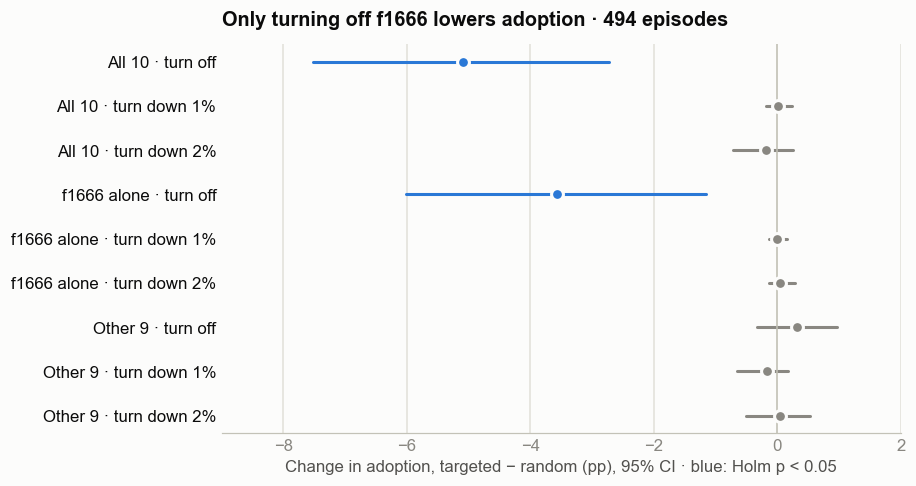

Features · edit,Targeted − random (pp),95% CI,p (Holm),Edit size targeted / random (%)
All 10 · turn off,-5.090000,"[-7.52, -2.73]",0.0006,86.1 / 3.3
All 10 · turn down 1%,0.010000,"[-0.19, 0.23]",1.00,1.0 / 1.0
All 10 · turn down 2%,-0.180000,"[-0.72, 0.25]",1.00,2.0 / 1.9
f1666 alone · turn off,-3.570000,"[-6.01, -1.16]",0.009,85.4 / 1.3
f1666 alone · turn down 1%,0.000000,"[-0.14, 0.15]",1.00,1.0 / 0.8
f1666 alone · turn down 2%,0.050000,"[-0.14, 0.29]",1.00,2.0 / 1.1
Other 9 · turn off,0.320000,"[-0.33, 0.96]",0.34,2.7 / 2.8
Other 9 · turn down 1%,-0.170000,"[-0.66, 0.17]",1.00,1.0 / 1.0
Other 9 · turn down 2%,0.040000,"[-0.51, 0.53]",1.00,1.9 / 1.9


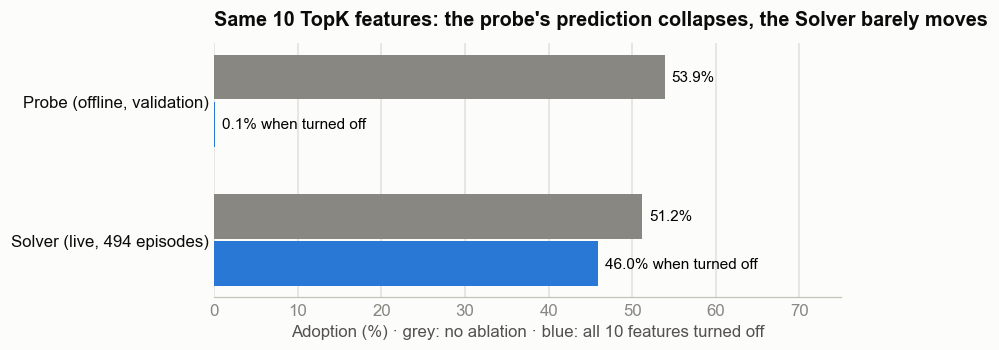

"Same 10 TopK features, same 1% edit",Targeted − random (pp),95% CI
"Probe (offline, validation)",-2.470000,"[-2.78, -2.19]"
"Solver (live, 494 episodes)",0.010000,"[-0.19, 0.23]"


In [5]:
GROUPS = {"All 10": "TopK SAE · error-preserving", "f1666 alone": "TopK SAE · f1666 · error-preserving", "Other 9": "TopK SAE · without_1666 · error-preserving"}
ARMS = {"ablation": ("turn off", "ablation"), "norm_-0.01": ("turn down 1%", "suppress (|Δ| ≤ 0.01·|x|)"), "norm_-0.02": ("turn down 2%", "suppress (|Δ| ≤ 0.02·|x|)")}
rows, table = [], []
for g, e in GROUPS.items():
    for arm, (edit, cond) in ARMS.items():
        t = one(tvr, Experiment=e, Arm=arm, Control="matched features", Rows="all")
        lo, hi = ci(t["95% CI (questions + draws)"]); p = float(t["p-value (Holm)"])
        size = lambda side: 100 * float(one(topk_diag, Experiment=e, Condition=f"{side} {cond}")["Mean edit norm (rel. to |x|)"])
        rows.append((f"{g} · {edit}", float(t["Targeted − random (pp)"]), lo, hi, p < 0.05))
        table.append({"Features · edit": f"{g} · {edit}", "Targeted − random (pp)": round(float(t["Targeted − random (pp)"]), 2),
                      "95% CI": t["95% CI (questions + draws)"], "p (Holm)": fmt_p(p), "Edit size targeted / random (%)": f"{size('Targeted'):.1f} / {size('Random'):.1f}"})
fig, ax = axes(f"Only turning off f1666 lowers adoption · {topk_labels['n_analysis_episodes']} episodes", size=(9.5, 4.6), left=0.25)
forest(ax, rows, (-9, 2)); ax.set_xlabel("Change in adoption, targeted − random (pp), 95% CI · blue: Holm p < 0.05")
save(fig, "3a_exp1_effects")
show(pd.DataFrame(table), "3a_exp1_effects")

pr = lambda c: float(one(proxy, Experiment="TopK SAE", Condition=c)["Acceptance Rate (%)"])
lv = lambda c: float(one(topk_table, Experiment="TopK SAE · error-preserving", Condition=c)["Acceptance Rate (%)"])
fig, ax = axes("Same 10 TopK features: the probe's prediction collapses, the Solver barely moves", size=(9.5, 3.0), left=0.3)
for i, (label, before_, after_) in enumerate([("Probe's predicted adoption", pr("No ablation"), pr("Targeted ablation")),
                                             ("Solver's actual adoption", lv("No ablation (= plain replay)"), lv("Targeted ablation"))]):
    ax.barh(i - 0.17, before_, height=0.32, color=MUTED); ax.barh(i + 0.17, after_, height=0.32, color=BLUE)
    ax.text(before_ + 0.8, i - 0.17, f"{before_:.1f}%", va="center", fontsize=10); ax.text(after_ + 0.8, i + 0.17, f"{after_:.1f}% when turned off", va="center", fontsize=10)
ax.set_yticks([0, 1], ["Probe (offline, validation)", f"Solver (live, {topk_labels['n_analysis_episodes']} episodes)"]); ax.invert_yaxis()
ax.set_xlim(0, 75); ax.set_xlabel("Adoption (%) · grey: no ablation · blue: all 10 features turned off")
save(fig, "3b_probe_vs_solver")
off = next(r for r in matched["targeted_vs_random"]["TopK SAE"] if r["dose"] == 0.01)
live = one(tvr, Experiment="TopK SAE · error-preserving", Arm="norm_-0.01", Control="matched features", Rows="all")
show(pd.DataFrame([("Probe (offline, validation)", round(off["delta_pp"], 2), "[{:.2f}, {:.2f}]".format(*off["ci95_pp_questions_and_draws"])),
                   (f"Solver (live, {topk_labels['n_analysis_episodes']} episodes)", round(float(live["Targeted − random (pp)"]), 2), live["95% CI (questions + draws)"])],
                  columns=["Same 10 TopK features, same 1% edit", "Targeted − random (pp)", "95% CI"]), "3b_matched_1pct")

## 3c · Exp 1: did the decision switch, or did the answer break?

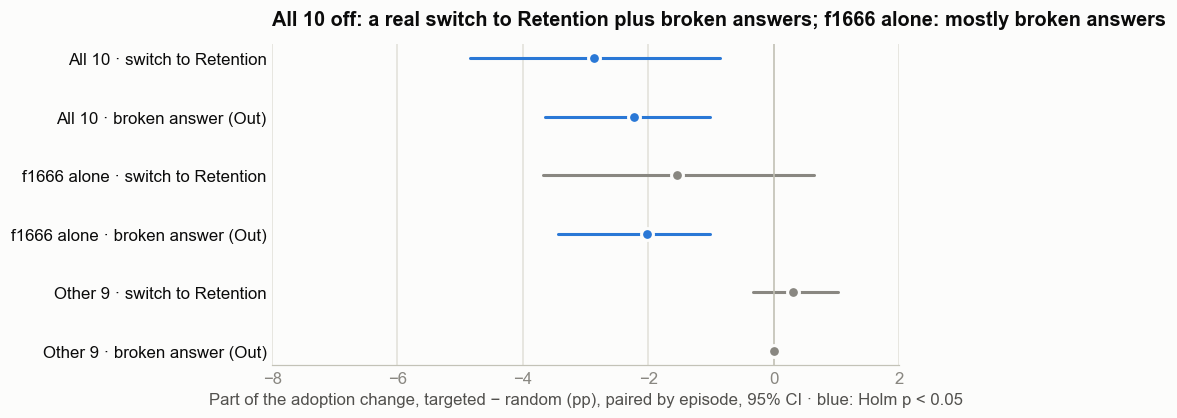

In [6]:
KINDS = {"A→R": ("adopted_critic", "retained_a1"), "R→A": ("retained_a1", "adopted_critic"),
         "A→Out": ("adopted_critic", "out"), "A→Agreement": ("adopted_critic", "unchanged_same_position")}
qids = [q for q in topk_eps.question_id if q not in set(topk_derived["empty_answer_questions"])]
assert len(qids) == topk_labels["n_analysis_episodes"] and not changed.duplicated(["question_id", "experiment", "condition", "draw"]).any()
pos, DRAWS = {q: i for i, q in enumerate(qids)}, topk_cfg["n_random_draws"]
def ind(exp, cond, nd):
    c = changed[(changed.experiment == exp) & (changed.condition == cond)]
    m = {k: np.zeros((len(qids), nd)) for k in KINDS}
    for k, (a, b) in KINDS.items():
        h = c[(c.solver_response_ctl == a) & (c.solver_response == b)]
        for q, dr in zip(h.question_id, h.draw):
            m[k][pos[q], 0 if nd == 1 else int(dr)] = 1
    return m
rng = np.random.default_rng(topk_cfg["seed"])
def paired(t, r):   # episodes paired; bootstrap over episodes and draws; sign-flip permutation over episodes
    diff, boot = t - r.mean(axis=1), []
    for _ in range(topk_cfg["n_bootstrap"]):
        e, d = rng.integers(0, len(t), len(t)), rng.integers(0, r.shape[1], r.shape[1])
        boot.append((t[e] - r[e][:, d].mean(axis=1)).mean())
    flips = rng.choice([-1.0, 1.0], size=(topk_cfg["n_permutations"], len(diff)))
    p = ((np.abs((flips * diff).mean(axis=1)) >= abs(diff.mean()) - 1e-12).sum() + 1) / (topk_cfg["n_permutations"] + 1)
    return 100 * diff.mean(), *(100 * np.percentile(boot, [2.5, 97.5])), p
parts = []
for g, e in GROUPS.items():
    t, r = ind(e, "targeted_ablation", 1), ind(e, "random_ablation", DRAWS)
    est = {"switch to Retention": paired(t["R→A"][:, 0] - t["A→R"][:, 0], r["R→A"] - r["A→R"]),
           "broken answer (Out)": paired(-t["A→Out"][:, 0], -r["A→Out"]),
           "other": paired(-t["A→Agreement"][:, 0], -r["A→Agreement"])}
    total = float(one(tvr, Experiment=e, Arm="ablation", Control="matched features", Rows="all")["Targeted − random (pp)"])
    assert abs(sum(v[0] for v in est.values()) - total) < 0.01, "parts must add up to the headline effect"
    parts += [(g, k, *v) for k, v in est.items() if k != "other" or abs(v[0]) >= 0.01]
P = pd.DataFrame(parts, columns=["group", "part", "m", "lo", "hi", "p"])
order = np.argsort(P.p.to_numpy()); adj, run = np.empty(len(P)), 0.0
for rank, i in enumerate(order):
    run = max(run, min(1.0, (len(P) - rank) * P.p.iloc[i])); adj[i] = run
P["p_holm"] = adj
fig, ax = axes("All 10 off: a real switch to Retention plus broken answers; f1666 alone: mostly broken answers", size=(9.5, 3.8), left=0.3)
forest(ax, [(f"{a.group} · {a.part}", a.m, a.lo, a.hi, a.p_holm < 0.05) for a in P.itertuples()], (-8, 2))
ax.set_xlabel("Part of the adoption change, targeted − random (pp), paired by episode, 95% CI · blue: Holm p < 0.05")
save(fig, "3c_switch_vs_broken")

## 4 · Control 1: the SAE alone (no ablation)

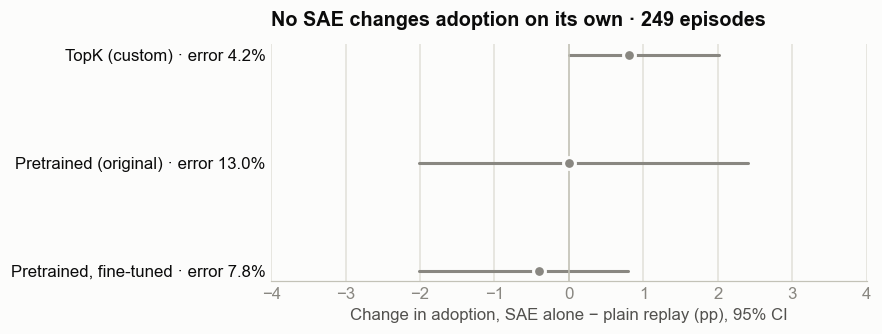

In [7]:
names = {"TopK SAE": "TopK (custom)", "Pretrained SAE": "Pretrained (original)", "Adapted pretrained SAE": "Pretrained, fine-tuned"}
rows = []
for e, label in names.items():
    r = one(damage, Experiment=e); lo, hi = ci(r["95% CI for Δ"])
    rows.append((f"{label} · error {100 * r['Mean reconstruction error (rel. to |x|)']:.1f}%", r["Δ (pp)"], lo, hi, False))
fig, ax = axes(f"No SAE changes adoption on its own · {int(damage.N.iloc[0])} episodes", size=(9.5, 2.8), left=0.33)
forest(ax, rows, (-4, 4)); ax.set_xlabel("Change in adoption, SAE alone − plain replay (pp), 95% CI")
save(fig, "4_control1")

## 5 · Exp 2 readiness (pretrained SAEs)

Check,Result
Fine-tuned keeps the original encoder,True
"Variance explained, original → fine-tuned",0.2246 → 0.7468


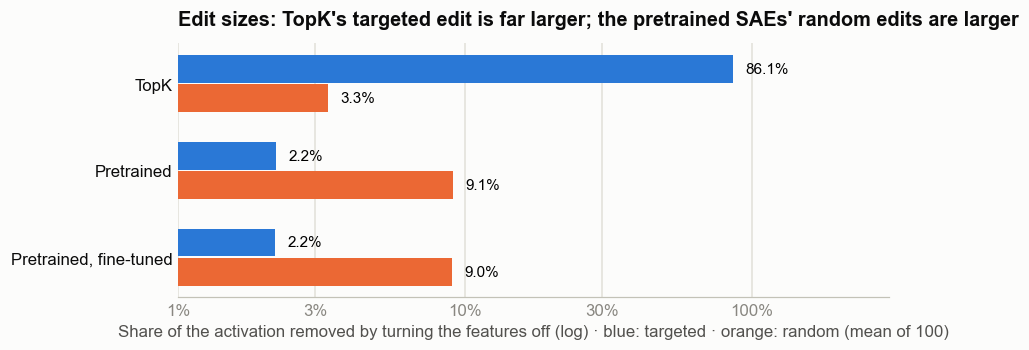

In [8]:
show(pd.DataFrame([("Fine-tuned keeps the original encoder", str(ft_summary["encoder_unchanged"])),
                   ("Variance explained, original → fine-tuned",
                    f"{ft_summary['original']['validation']['variance_explained']:.4f} → {ft_summary['adapted']['validation']['variance_explained']:.4f}")],
                  columns=["Check", "Result"]), "5a_checkpoints")
runa, topk_a = audit["Run A (causal_pretrained_layer25.yaml)"], audit["TopK (calibration, causal_topk_mixed_layer25.yaml)"]
sets = [("TopK", topk_a["TopK SAE · all 10"]), ("Pretrained", runa["Pretrained SAE · all 10"]), ("Pretrained, fine-tuned", runa["Adapted pretrained SAE · all 10"])]
fig, ax = axes("Edit sizes: TopK's targeted edit is far larger; the pretrained SAEs' random edits are larger", size=(9.5, 3.0), left=0.22)
for i, (label, r) in enumerate(sets):
    ax.barh(i - 0.17, 100 * r["targeted_mean"], height=0.32, color=BLUE); ax.barh(i + 0.17, 100 * r["random_mean"], height=0.32, color=ORANGE)
    ax.text(100 * r["targeted_mean"] * 1.1, i - 0.17, f"{100 * r['targeted_mean']:.1f}%", va="center", fontsize=10)
    ax.text(100 * r["random_mean"] * 1.1, i + 0.17, f"{100 * r['random_mean']:.1f}%", va="center", fontsize=10)
ax.set_xscale("log"); ax.set_xlim(1, 300); ax.set_xticks([1, 3, 10, 30, 100], ["1%", "3%", "10%", "30%", "100%"]); ax.minorticks_off(); ax.set_yticks(range(len(sets)), [s[0] for s in sets]); ax.invert_yaxis()
ax.set_xlabel("Share of the activation removed by turning the features off (log) · blue: targeted · orange: random (mean of 100)")
save(fig, "5b_edit_sizes")

## 6 · Where we are

In [9]:
RUN_A = "11/50 shards as of 18:02 ET, finishes ~21:25 ET tonight"   # Run A runs on the EC2 workers: timestamped status, not a result
t10 = one(tvr, Experiment="TopK SAE · error-preserving", Arm="ablation", Control="matched features", Rows="all")
show(pd.DataFrame([
    ("Baseline", "Done", "replays match stored answers"),
    ("Exp 1 · TopK · targeted + random", "Done", f"{float(t10['Targeted − random (pp)']):+.1f} pp (Holm p {fmt_p(float(t10['p-value (Holm)']))})"),
    ("Control 1 · all three SAEs", "Done", "no change in adoption"),
    ("Exp 2 · original + fine-tuned pretrained · targeted + random", "Running", RUN_A),
    ("L1 SAE, Raw activations", "Pending", "after Run A"),
    ("Part 2 · LLM on dense activations", "Pending", "after the causal comparisons"),
], columns=["Condition", "Status", "Evidence"]), "6_status")
AFTER = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}
assert AFTER == BEFORE, "inputs changed while the notebook ran"
(OUT / "tables" / "inputs_sha256.json").write_text(json.dumps(BEFORE, indent=2) + "\n")

Condition,Status,Evidence
Baseline,Done,replays match stored answers
Exp 1 · TopK · targeted + random,Done,-5.1 pp (Holm p 0.0006)
Control 1 · all three SAEs,Done,no change in adoption
Exp 2 · original + fine-tuned pretrained · targeted + random,Running,"11/50 shards as of 18:02 ET, finishes ~21:25 ET tonight"
"L1 SAE, Raw activations",Pending,after Run A
Part 2 · LLM on dense activations,Pending,after the causal comparisons


4090

## 7 · Next
1. Tonight: Run A results (Exp 2), paired with TopK on identical episodes.
2. L1 and Raw activations, same episodes, same standard.
3. All ~3,518 eligible episodes for every representation (an episode-range option first).
4. Part 2: an LLM on the dense activations.